In [2]:
import numpy as np
import matplotlib.pyplot as plt
import re
import os
import ase.io as aio



In [3]:

def  make_folder(folder_name):
     if not os.path.exists(folder_name):
        os.mkdir(folder_name)
        
        
        
def create_file(filename):
    with open(filename, 'w'):
        pass 


def make_empty_folder(folder_name):
    if not os.path.exists(folder_name):
        os.mkdir(folder_name)
    else:
        try:
            # List all files in the directory
            files = os.listdir(folder_name)

            # Iterate over each file and remove it
            for file in files:
                file_path = os.path.join(folder_name, file)
                if os.path.isfile(file_path):
                    os.remove(file_path)
                    #print(f"File '{file_path}' removed successfully.")
        except OSError as e:
            print(f"Error: {e.strerror}")

def find_folder_by_name(root_path, folder_name):
    folders=[]
    
    for root, dirs, files in os.walk(root_path):
        if folder_name in dirs:
             folders.append(os.path.join(root, folder_name))
    return np.sort(folders)


In [4]:
def get_initial_info(trj):
    pattern= r"TIMESTEP"
    header=8
    N_H=0
    N_O=0
    N_Fe=0
    #SCV structure (1uc)
    N_OS_uc=8    # number oxygen in first outer layer/uc
    N_FeS_uc=4   # number of iron in first outer layer/uc
    N_FeS2_uc=3  # number of iron  second/outer layer/uc
    with open(trj, 'r') as file:

        for count, line in enumerate(file):     
            if  re.search(pattern, line) and count !=0 :
                break
                
            split_line=line.split()   
            if count == 3:
                N_atom=float(split_line[0])
            if count == 5:
                L_x=float(split_line[1])
            if count == 7:
                L_z=float(split_line[1])
            #position block
            if count > header:        
                if split_line[1] == '1':
                   N_H+=1
                if split_line[1] == '2':
                   N_O+=1   
                if split_line[1] == '3':
                   N_Fe+=1   
        L_y=L_x
        
        #replica
        for n in range(1,10):
            if 8 < L_x/n < 9:
                n_replica=n
                
        if N_atom != N_H+N_O+N_Fe:
            print("ATOM LOST")
        
        f=n_replica**2
        N_water=int(N_H/2)
        N_Fe_uc=int(N_Fe/f)
        N_O_uc=int((N_O-N_water)/f)
        w_uc=float(N_water/f/2)
        N_OS=N_OS_uc*f
        N_FeS=N_FeS_uc*f
        N_FeS2= N_FeS2_uc*f
        diag_lenght=np.sqrt(L_x**2+L_y**2)
        print("L_x = L_y = ", L_x)
        print("L_z = ", L_z)
        print("Diagonal= ", diag_lenght)
        print("N_O_uc = ",  N_O_uc)
        print("N_Fe_uc =",  N_Fe_uc)
        print("w_uc =",  w_uc)
        print(f"Size factor f = {f}")
        print(f"N_water = {N_water}")
        print(f"N_H = {N_H}")
        print(f"N_O = {N_O}")
        print(f"N_Fe = {N_Fe}")
        print(f"N_atom = {N_atom}")
        print(f"N_O surface = {N_OS}")
        print(f"N_Fe surface = {N_FeS}")
        print(f"N_Fe surface2 = {N_FeS2}")
        
        return(f, L_x, L_y, L_z, diag_lenght, N_water,  N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2)

In [5]:

#takes: atoms in a layer
#determine exactly the surfaces positions with average of z of all atom in the surface: 
def get_layer_z(A):
    z=A[:,2]
    return np.mean(z), max(z), min(z)

def slice_height(A, z_max):
    tmp=[]
    for a in A:
        if a[2]<=z_max:
            tmp.append(a)
    return np.array(tmp)


In [6]:
#oct and tet analysis based on oxygens surface layer: OS_u or OS_d as input, box xy diagonal, and  cluster parm epsilon =1

#output diagonal O raws displacment to separate (Fe) oct and tet zones
def get_diagonal_O_raws(OS_u, control, diag_lenght,  epsilon):
    diagonal_projection=[]

    
    for atom in OS_u:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
        #print(theta)
        if control == 'u':
            diagonal_projection.append(r*np.cos(theta - (np.pi/4)  )   )
        elif control == 'd':
            diagonal_projection.append(r*np.sin(theta - (np.pi/4)  )   )
        else:
            print("control must be 'u' or 'd'")
            return

    #clusterization of diagonal projection of O position in raws
    cluster_diag_proj=[]
    
    cluster_diag_proj.append([diagonal_projection[0]])

    for i, proj in enumerate(diagonal_projection[1:]):
        copy=cluster_diag_proj
     
        for j in range(len(copy)):
            #print(j)
            if np.abs(proj-cluster_diag_proj[j][0])<epsilon:
                cluster_diag_proj[j].append(proj)
                #print("existing")
                break
            elif j==len(copy)-1:      #last round and no match found create new entry
                #print("new")
                cluster_diag_proj.append([proj])
   
    
    #buffering oct region
    cluster_diag_proj=np.sort(cluster_diag_proj)
    diag_raws_buffer=[]   
    if (np.mean(cluster_diag_proj[1])-np.mean(cluster_diag_proj[0]))< (np.mean(cluster_diag_proj[2])-np.mean(cluster_diag_proj[1])): #oct raw first
        for n, cluster in enumerate(cluster_diag_proj):
            if n % 2 == 0:
                diag_raws_buffer.append(np.max(cluster))
            else:
                diag_raws_buffer.append(np.min(cluster))
    else: #tet raw first
        for n, cluster in enumerate(cluster_diag_proj):
            if n % 2 == 0:
                diag_raws_buffer.append(np.min(cluster))
            else:
                diag_raws_buffer.append(np.max(cluster))
   
    if control == 'u':
        diag_raws_buffer.insert(0,0)
        diag_raws_buffer.append(diag_lenght)
    else:
        diag_raws_buffer.insert(0,-diag_lenght/2)
        diag_raws_buffer.append(diag_lenght/2)
    #print(diag_raws_buffer)
    return diag_raws_buffer
        
        
    
#oct/tet regions atomic separation; inside O raws = oct, outside = tet: 
                    #combo == combined [Oxgen, OH dipole ecc]
def oct_tet_split_combo(combo, diag_raw , control):
      
    oct_combo=[]
    tet_combo=[]
    
    
    for atom , bond in combo:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
    
        if control == 'u':
            diagonal_projection=(r*np.cos(theta - (np.pi/4)  ))     #up cos raws   \\\\\           
        elif control == 'd':
            diagonal_projection=(r*np.sin(theta - (np.pi/4)  ))     #down sin raws  /////   
            
        else:  
            print("control must be 'u' or 'd'")
            return   
        
        if diagonal_projection <diag_raw[0] or diagonal_projection > diag_raw[-1]:  #inbound check
                print("OUT of bounds: diag =" , diagonal_projection, "cartesian =", atom)
        #diag raws contain the 0 and the diag)lenght!        
        if (diag_raw[2]-diag_raw[1])<(diag_raw[3]-diag_raw[2]):           #check if the first raw (the zero is the border)is oct or tet (if T == oct if F ==tet )
            # first raw is oct
            #if diagonal projection in (diag_raw[2n],diag_raw[2n+1])   then tet region  even!
            #if diagonal projection in (diag_raw[2n+1],diag_raw[2n+2]) then oct region odd!
            for n in range(len(diag_raw)-1):  
                if  diagonal_projection == diag_raw[n+1]: 
                    tet_combo.append([atom, bond])      #borders are tet
                    #print('tet found')
                if diag_raw[n] < diagonal_projection < diag_raw[n+1]: 
                    if n % 2 ==0:
                        tet_combo.append([atom, bond]) #n even ==> outside O raws == tet region
                        #print('tet found')
                    else:
                        oct_combo.append([atom, bond]) #n odd ==> inside O raws == oct region
                        #print('oct found')
                    break
        else:
            #first raw is tet (then vice versa)        
            for n in range(len(diag_raw)-1):
                if  diagonal_projection == diag_raw[n+1]: 
                    tet_combo.append([atom, bond])      #borders are tet  
                if diag_raw[n] < diagonal_projection < diag_raw[n+1]: 
                    if n % 2 ==0:
                        oct_combo.append([atom, bond]) #n even ==> inside O raws == oct region
                    else:
                        tet_combo.append([atom, bond]) #n odd ==> outside O raws == tet region
                    break
        
    if len(oct_combo)+len(tet_combo) != len(combo):
        print("MISSING TET/OCT ATOM: ",len(combo)-  (len(oct_combo)+len(tet_combo))) 
    return oct_combo,  tet_combo

In [7]:
#oct/tet regions atomic separation; inside O raws = oct, outside = tet: 
def tet_oct_split_correct_tet(O_u, diag_raw , control ):
      
    O_oct_u=[]
    O_tet_u=[]
   
    for atom in O_u:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
    
        if control == 'u':
            diagonal_projection=(r*np.cos(theta - (np.pi/4)  ))     #up cos raws   \\\\\           
        elif control == 'd':
            diagonal_projection=(r*np.sin(theta - (np.pi/4)  ))     #down sin raws  /////   
            
        else:  
            print("control must be 'u' or 'd'")
            return   
        
        if diagonal_projection <diag_raw[0] or diagonal_projection > diag_raw[-1]:  #inbound check
                print("OUT of bounds: diag =" , diagonal_projection, "cartesian =", atom)
                
        if (diag_raw[2]-diag_raw[1])<(diag_raw[3]-diag_raw[2]):           #check if the first raw (the zero is the border)is oct or tet (if T == oct if F ==tet )
            # first raw is oct
            #if diagonal projection in (diag_raw[2n],diag_raw[2n+1])   then tet region  even!
            #if diagonal projection in (diag_raw[2n+1],diag_raw[2n+2]) then oct region odd!
            for n in range(len(diag_raw)-1):  
                if diagonal_projection == diag_raw[n]:
                    O_tet_u.append([atom[0], atom[1], atom[2]]) #borders are tet
                    #print('tet', diagonal_projection)
                if diag_raw[n] < diagonal_projection < diag_raw[n+1]: 
                    if n % 2 ==0:
                        O_tet_u.append([atom[0], atom[1], atom[2]]) #n even ==> outside O raws == tet region
                        #print('tet', diagonal_projection)
                    else:
                        O_oct_u.append([atom[0], atom[1], atom[2]]) #n odd ==> inside O raws == oct region
                        #print('oct', diagonal_projection)
                    break
             
        else:
            #first raw is tet
            for n in range(len(diag_raw)-1):
                if diagonal_projection == diag_raw[n]:
                    O_tet_u.append([atom[0], atom[1], atom[2]]) #borders are tet 
                if diag_raw[n] < diagonal_projection < diag_raw[n+1]: 
                    if n % 2 ==0:
                        O_oct_u.append([atom[0], atom[1], atom[2]]) #n even ==> inside O raws == oct region
                    else:
                        O_tet_u.append([atom[0], atom[1], atom[2]]) #n odd ==> outside O raws == tet region
                    break
            
        
    if len(O_oct_u)+len(O_tet_u) != len(O_u):
        print("MISSING TET/OCT ATOM: ",len(O_u)-  (len(O_oct_u)+len(O_tet_u))) 
    return O_oct_u,  O_tet_u

In [8]:
def vector_distance_pbc(u,v , L_x, L_y, L_z):
    difference=[]
    
    dx=u[0]-v[0]
    dy=u[1]-v[1]
    dz=u[2]-v[2]
    
    if np.abs(dx) <= L_x/2:
        difference.append(dx)
    elif dx>0:
        difference.append(dx - L_x)
    else:
        difference.append(dx + L_x)
    
    if np.abs(dy) <= L_y/2:
        difference.append(dy)
    elif dy>0:
        difference.append(dy- L_y)
    else:
        difference.append(dy + L_y)
    
    if np.abs(dz) <= L_z/2:
        difference.append(dz)
    elif dz>0:
        difference.append(dz- L_z)
    else:
        difference.append(dz+ L_z)
    
    return np.array(difference)


import math
def cartesian_internal(u, phi_pi_periodicity ):  
    x=u[0]
    y=u[1]
    z=u[2]
    # Calculate radial distance
    r = math.sqrt(x**2 + y**2 + z**2)

    # Calculate polar angle (theta)
    theta = math.acos(z / r) if r != 0 else 0

    # Calculate azimuthal angle (phi)
    phi = math.atan2(y, x)
    if phi_pi_periodicity:
        if phi<0:
            phi = phi+np.pi

    return np.array([r, theta, phi])   

In [9]:
def get_O_cartesian_OH_internal(H_u_indx, O, H, L_x,L_y, z_max_vacuum, t):
    water_dipole=[]
    OHHH=[]
    OH_water=[]
    OH=[]
    O_alone=[]
    
    
    for i , H_index in enumerate(H_u_indx):

        if len(H_index)==0: 
                #if  O[i][2]>3.7:
                #       print(t,"attention! z O alone =",  O[i][2] )
                O_alone.append(O[i])

        elif len(H_index)==1: 

                OH_internal=cartesian_internal(vector_distance_pbc(H[H_index[0]],O[i]  , L_x, L_y, z_max_vacuum))
                OH.append([O[i],OH_internal])
                
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OH =",  O[i][2] )
                
        elif len(H_index)==2:
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                dipole=OH_cartesian_0+OH_cartesian_1
                
                OH_internal_0=cartesian_internal(OH_cartesian_0)
                OH_internal_1=cartesian_internal(OH_cartesian_1)
                dipole_internal=cartesian_internal(dipole)
                
                OH_water.append([O[i],OH_internal_0])
                OH_water.append([O[i],OH_internal_1])
                water_dipole.append([O[i],dipole_internal] )

        elif len(H_index)==3:
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OHHH =",  O[i][2] )
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_2=vector_distance_pbc(H[H_index[2]], O[i] , L_x, L_y, z_max_vacuum)
                OH_internal_0=cartesian_internal(OH_cartesian_0)
                OH_internal_1=cartesian_internal(OH_cartesian_1)
                OH_internal_2=cartesian_internal(OH_cartesian_2)
                
                OHHH.append([O[i],OH_internal_0])
                OHHH.append([O[i],OH_internal_1])
                OHHH.append([O[i],OH_internal_2])
                
        else:
              print( "attention! found H*O=", H_index, "at z=", O[i][2])  
    return water_dipole , OH_water , OH, OHHH, O_alone

In [10]:
def get_O_cartesian_OH_internal_water_plus_H3O(H_u_indx, O, H, L_x,L_y, z_max_vacuum, t, phi_pi_periodicity):
    water_dipole=[]
 
    OH_water=[]
    OH=[]
    O_alone=[]
    
    
    for i , H_index in enumerate(H_u_indx):

        if len(H_index)==0: 
                #if  O[i][2]>3.7:
                #       print(t,"attention! z O alone =",  O[i][2] )
                O_alone.append(O[i])

        elif len(H_index)==1: 

                OH_internal=cartesian_internal(vector_distance_pbc(H[H_index[0]],O[i]  , L_x, L_y, z_max_vacuum), phi_pi_periodicity)
                OH.append([O[i],OH_internal])
                
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OH =",  O[i][2] )
                
        elif len(H_index)==2:
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                dipole=OH_cartesian_0+OH_cartesian_1
                
                OH_internal_0=cartesian_internal(OH_cartesian_0, phi_pi_periodicity)
                OH_internal_1=cartesian_internal(OH_cartesian_1, phi_pi_periodicity)
                dipole_internal=cartesian_internal(dipole, phi_pi_periodicity)
                
                OH_water.append([O[i],OH_internal_0])
                OH_water.append([O[i],OH_internal_1])
                water_dipole.append([O[i],dipole_internal] )
                
        elif len(H_index) >= 3:
                #if  O[i][2]>3.7:
                #       print(t,"attention! z of H", len(H_index), "H =",  O[i][2] )
                
                
                for h in range(len(H_index)):
                
                        OH_cartesian=vector_distance_pbc(H[H_index[h]], O[i] , L_x, L_y, z_max_vacuum)
                        OH_internal=cartesian_internal(OH_cartesian, phi_pi_periodicity)
                        OH_water.append([O[i],OH_internal])
     
    return water_dipole , OH_water , OH,  O_alone

In [11]:
def OH_z_layer_grouping(O_bond_format,  layer_bins):
    

    # Group arrays based on bins
    grouped_arrays = {category: [] for category in layer_bins}

    for combo in O_bond_format:
        O_z=combo[0][2]
        OH_internal=combo[1]
        for category, condition in layer_bins.items():
            if condition(O_z):
                grouped_arrays[category].append(OH_internal)
                break  # Break out of the loop after categorizing the array

    return grouped_arrays


In [12]:

def dict_bins_maker(names,layers):  #name of the z layers and layers contain  min and max value
    layer_bins={}
    

    for i, key in enumerate(names):
        layer_bins[key] = (lambda i=i: lambda x: layers[i] < x <= layers[i + 1])()
    
    return  layer_bins

def init_bins_rho_theta_phi(n_bin, delta, phi_pi_periodicity):
    
    rho_bins   = np.linspace(0.8, delta, n_bin) # arbitrary interval (delta is the cutoff)
    theta_bins = np.linspace(-1, 1, n_bin) 
    if phi_pi_periodicity:
        phi_bins   = np.linspace(0 , np.pi , n_bin)
    else:
        phi_bins   = np.linspace(-np.pi, np.pi , n_bin) 
    
    rho_bins_centers=(rho_bins[1:]+rho_bins[:-1])/2
    theta_bins_centers=(theta_bins[1:]+theta_bins[:-1])/2
    phi_bins_centers=(phi_bins[1:]+phi_bins[:-1])/2   
    
    return   rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers


def init_combo_hist(layer_bins, n_bin):
    #histograms
   
    combo_hist  = {}

    
    # lenght to normalize
    
    hist_normalization= {}

    
    for layer in layer_bins.keys():
      
        combo_hist[layer]  =[[0]*(n_bin-1)]*(n_bin-1)

        hist_normalization[layer] = 0

    return combo_hist, hist_normalization



In [13]:

def sum_combo_hist(OH_grouped, combo_hist, theta_bins, phi_bins , hist_normalization,  density_bool ):

    for layer, bonds in OH_grouped.items():
        if len(bonds) !=0:
            theta=np.transpose(np.array(bonds))[1]
            phi=np.transpose(np.array(bonds))[2]    
            hist_normalization[layer]+=len(theta)
            combo_hist[layer]+=np.histogram2d( np.cos(theta), phi,    bins=[ theta_bins,  phi_bins] , density=density_bool )[0]
      
    return combo_hist, hist_normalization

In [14]:
def sum_hist_rho_theta_phi(OH_grouped, rho_hist, theta_hist, phi_hist, rho_bins, theta_bins,  phi_bins,  hist_normalization,  phi_sin_theta_normalization, density_bool, phi_sin_weight_bool):

    for layer, bonds in OH_grouped.items():
        if len(bonds) !=0:
            rho=np.transpose(np.array(bonds))[0]
            theta=np.transpose(np.array(bonds))[1]
            phi=np.transpose(np.array(bonds))[2]    
            
            rho_hist[layer]  +=np.histogram(rho, bins=rho_bins, density=density_bool)[0]
            theta_hist[layer]+=np.histogram(np.cos(theta), bins=theta_bins,  density=density_bool)[0]
           
            #normalization: count how many points in the hist are put in every passage  
            hist_normalization[layer]+=len(theta)
            
            if phi_sin_weight_bool:
                phi_weights=np.sin(theta)
                phi_hist[layer]  +=np.histogram(phi, bins=phi_bins, weights=phi_weights,  density=density_bool )[0] 
                #weighted normalization
                phi_sin_theta_normalization[layer]+=np.sum(np.sin(theta))
            else:
                phi_hist[layer]  +=np.histogram(phi, bins=phi_bins,  density=density_bool )[0]  
                
            
            
    return  rho_hist, theta_hist, phi_hist ,hist_normalization , phi_sin_theta_normalization


def sum_hist_theta_phi(OH_grouped, theta_hist, phi_hist, theta_bins, phi_bins ,density_bool,phi_sin_weight_bool ):

    for layer, bonds in OH_grouped.items():
        if len(bonds) !=0:
            theta=np.transpose(np.array(bonds))[1]
            phi=np.transpose(np.array(bonds))[2]    
            
            theta_hist[layer]+=np.histogram(np.cos(theta), bins=theta_bins,  density=density_bool)[0]
            
            
            
            if phi_sin_weight_bool:
                phi_weights=np.sin(theta)
                phi_hist[layer]  +=np.histogram(phi, bins=phi_bins, weights=phi_weights,  density=density_bool )[0]   
            else:
                phi_hist[layer]  +=np.histogram(phi, bins=phi_bins,  density=density_bool )[0]   
                
    return theta_hist, phi_hist   
    

In [15]:
def safe_concatenate(a,b):
    if len(a)==0:
        return b
    elif len(b)==0:
        return a
    else:
        return np.concatenate((a,b),axis=0) 

In [41]:
path_of_runs='/data/home/salvatorer26/projects/ferrite_oxide/production/production_runs/'
run_folder='full_coverage_big/run_2/'

file_trj=path_of_runs + run_folder +'trjmagnetite.dump'
h5py_files_folder=path_of_runs+ run_folder+"trajectory_h5py_files/" 

f, L_x, L_y, L_z, diag_lenght, N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2= get_initial_info(file_trj)
print(h5py_files_folder)

surface_selection='u'



control_u='u'   #DONT  #surface down already adjusted in h5py file

delta=1.2

#z_max=41-delta       #max distance from the surface for O 25 or 40   
z_max=7.3
z_max_H=z_max+delta           #max distance from the surface for H (delta above to include the missing H at the cut)
z_max_vacuum= z_max+4*delta   #another delta of vacuum distance on top to avoid wrong PBC count


density_bool=False           # density histogram directly 
phi_sin_weight_bool=False    # True: sin(theta) weighted average for phi  (2D plot always False!)
phi_pi_periodicity=True        #Set True if you want phi from 0 to pi 
#H tree box for bonding
box_size = np.array([L_x, L_y, z_max_vacuum])  


# Histograms Init 

# Define binning
n_bins=120  #common number of bins


#z layer layers (all, oct, tet)
layers     =[-0.5,  1,  3.6,  7.3]
layers_oct =[ -0.5,   3.1,  5.1,  7.3]
layers_tet =[-0.5,  1, 2.12,  4.1,    7.3]

#z layer layers (all, oct, tet)
#layers     =[-0.5, 1, 3.6, 7.2, 10.6 , 13.8, 17,  21, 25, 29, 33, 37, 41-delta ]
#layers_oct =[ -0.5,   3.1,   5.1, 7.3  , 10,  13.5]
#layers_tet =[-0.5,  1, 2.12,  4.1, 7,    10.7]

# Define name of bins (all, oct, tet)
names    =["l_"+str(i) for i in np.arange(0,len(layers)-1)]
names_oct=[ "first",    "second (a)", "second (b)"]
names_tet=["dissociated", "first (a)", "first (b)", "second"]


L_x = L_y =  33.584
L_z =  103.0138
Diagonal=  47.49494827873803
N_O_uc =  72
N_Fe_uc = 50
w_uc = 98.5
Size factor f = 16
N_water = 3152
N_H = 6304
N_O = 4304
N_Fe = 800
N_atom = 11408.0
N_O surface = 128
N_Fe surface = 64
N_Fe surface2 = 48
/data/home/salvatorer26/projects/ferrite_oxide/production/production_runs/full_coverage_big/run_2/trajectory_h5py_files/


In [42]:
import h5py
from scipy.spatial import cKDTree




# Init bins as dictionary with key as layers (all, oct, tet)
layer_bins    =dict_bins_maker(names,layers)
layer_bins_oct=dict_bins_maker(names_oct,layers_oct)
layer_bins_tet=dict_bins_maker(names_tet,layers_tet)

#initialize bins of rho, theta, phi  and respective bin centers
rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers=init_bins_rho_theta_phi(n_bins, delta, phi_pi_periodicity)

d_rho=(rho_bins[-1]-rho_bins[0])/(n_bins-1)
d_theta=(theta_bins[-1]-theta_bins[0])/(n_bins-1)
d_phi=(phi_bins[-1]-phi_bins[0])/(n_bins-1)

#initialize histograms with zeros
combo_hist_OH      ,  norm_hist_OH        =    init_combo_hist(layer_bins, n_bins)
combo_hist_OH_water,  norm_hist_OH_water  =    init_combo_hist(layer_bins, n_bins)
combo_hist_dipole  ,  norm_hist_dipole    =    init_combo_hist(layer_bins, n_bins) 
 

combo_hist_OH_oct       ,         norm_hist_OH_oct   =init_combo_hist(layer_bins_oct, n_bins)
combo_hist_OH_water_oct ,   norm_hist_OH_water_oct  = init_combo_hist(layer_bins_oct, n_bins)
combo_hist_dipole_oct   ,     norm_hist_dipole_oct  = init_combo_hist(layer_bins_oct, n_bins)   

combo_hist_OH_tet       ,         norm_hist_OH_tet  = init_combo_hist(layer_bins_tet, n_bins)
combo_hist_OH_water_tet ,   norm_hist_OH_water_tet  = init_combo_hist(layer_bins_tet, n_bins)
combo_hist_dipole_tet   ,     norm_hist_dipole_tet  = init_combo_hist(layer_bins_tet, n_bins)



#TIME LOOP BEGIN
t=0
h5py_str='.h5py'
with h5py.File(h5py_files_folder+"H_"+surface_selection+h5py_str, 'r') as f_H, h5py.File(h5py_files_folder+"O_"+surface_selection+h5py_str, 'r') as f_O, h5py.File(h5py_files_folder+"OS_"+surface_selection+h5py_str, 'r') as f_OS:
    for k in f_H.keys(): #main time loop
      
        H = f_H[k][:]
        O = f_O[k][:]
        OS = f_OS[k][:]
   
        #oct/tet raws
        diag_raw=get_diagonal_O_raws(OS, control_u, diag_lenght, 1 )
           
        #add oxygen at surface to get the OH bond of dissociation
        all_O=np.concatenate((O,OS))
        #select atoms O till z_max and H z_max+delta to not beark any bond
        O=slice_height(all_O, z_max)  
        H=slice_height(H, z_max_H)  

        #H index is a list of list of H indices: the 0 index is the Oxygen, the second runs from 0 to the N_H that are within a cutoff delta to that O 
        tree = cKDTree(data=H, leafsize=H.shape[0], boxsize= box_size)  #makes a tree of Hs
        H_indx = tree.query_ball_point(O, delta)                        #assign every H to an O within the cutoff and make the list of list H

        #extract from the H_indx the Oxygen in cartesian and the OH(s)in polar:
        #the output is then a list of pair [O_vect, OH]
        #dipole , OH_water , OH, O_HHH, O_alone=get_O_cartesian_OH_internal(H_indx, O, H, L_x,L_y, z_max_vacuum, t)   #not periodic distance for the z direction
        dipole , OH_water , OH, O_alone=get_O_cartesian_OH_internal_water_plus_H3O(H_indx, O, H, L_x,L_y, z_max_vacuum, t, phi_pi_periodicity)   #not periodic distance for the z direction

        #OCT/TET splitting #all control are up because of the down correction while splitting up and down
        dipole_oct,   dipole_tet   =oct_tet_split_combo(dipole,   diag_raw , control_u )
        OH_water_oct, OH_water_tet =oct_tet_split_combo(OH_water, diag_raw , control_u )
        OH_oct,       OH_tet       =oct_tet_split_combo(OH,       diag_raw , control_u )

        #use the info of the z Oxygen to group the OH by their heights: output is dictonary with layer_bins keys and vlues OH in internal
        dipole_z  = OH_z_layer_grouping(dipole,   layer_bins)
        OH_water_z= OH_z_layer_grouping(OH_water, layer_bins)
        OH_z      = OH_z_layer_grouping(OH,       layer_bins)
        
        dipole_z_oct  = OH_z_layer_grouping(dipole_oct,   layer_bins_oct)
        OH_water_z_oct= OH_z_layer_grouping(OH_water_oct, layer_bins_oct)
        OH_z_oct      = OH_z_layer_grouping(OH_oct,       layer_bins_oct)

        dipole_z_tet  = OH_z_layer_grouping(dipole_tet,   layer_bins_tet)
        OH_water_z_tet= OH_z_layer_grouping(OH_water_tet, layer_bins_tet)
        OH_z_tet      = OH_z_layer_grouping(OH_tet,       layer_bins_tet)

        #Sum the histograms
        combo_hist_OH      ,  norm_hist_OH,         = sum_combo_hist(OH_z,       combo_hist_OH,       theta_bins, phi_bins,   norm_hist_OH,       density_bool)
        combo_hist_OH_water,  norm_hist_OH_water,   = sum_combo_hist(OH_water_z, combo_hist_OH_water, theta_bins, phi_bins,   norm_hist_OH_water, density_bool )
        combo_hist_dipole  ,  norm_hist_dipole,     = sum_combo_hist(dipole_z,   combo_hist_dipole,   theta_bins, phi_bins,   norm_hist_dipole,   density_bool)
        
        combo_hist_OH_oct,         norm_hist_OH_oct,         = sum_combo_hist(OH_z_oct,       combo_hist_OH_oct,       theta_bins, phi_bins,   norm_hist_OH_oct,       density_bool) 
        combo_hist_OH_water_oct,   norm_hist_OH_water_oct,   = sum_combo_hist(OH_water_z_oct, combo_hist_OH_water_oct, theta_bins, phi_bins,   norm_hist_OH_water_oct, density_bool ) 
        combo_hist_dipole_oct,     norm_hist_dipole_oct,     = sum_combo_hist(dipole_z_oct,   combo_hist_dipole_oct,   theta_bins, phi_bins,   norm_hist_dipole_oct,   density_bool) 
        
        combo_hist_OH_tet,         norm_hist_OH_tet,         = sum_combo_hist(OH_z_tet,       combo_hist_OH_tet,       theta_bins, phi_bins,   norm_hist_OH_tet,       density_bool) 
        combo_hist_OH_water_tet,   norm_hist_OH_water_tet,   = sum_combo_hist(OH_water_z_tet, combo_hist_OH_water_tet, theta_bins, phi_bins,   norm_hist_OH_water_tet, density_bool ) 
        combo_hist_dipole_tet,     norm_hist_dipole_tet,     = sum_combo_hist(dipole_z_tet,   combo_hist_dipole_tet,   theta_bins, phi_bins,   norm_hist_dipole_tet,   density_bool) 

        t+=1
            
     

/data/home/salvatorer26/.local/lib/python3.8/site-packages/numpy/core/fromnumeric.py:1003: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  a = asanyarray(a).copy(order="K")


In [43]:
print(np.sum(combo_hist_OH_water_tet['first (a)']))

norm_hist_OH_water_tet

345227.0


{'dissociated': 0,
 'first (a)': 345227,
 'first (b)': 1265430,
 'second': 1653694}

In [44]:
combo_hist_OH_water_tet['first (a)'][20]

array([  3.,   4.,   6.,  15.,  11.,  15.,  21.,  23.,  40.,  30.,  48.,
        88.,  95., 101., 135., 178., 216., 239., 281., 338., 387., 400.,
       487., 499., 594., 628., 645., 707., 671., 678., 721., 711., 651.,
       641., 580., 549., 476., 420., 363., 380., 292., 261., 204., 171.,
       164., 111.,  79.,  80.,  56.,  46.,  38.,  27.,  23.,  10.,  10.,
        11.,   8.,   7.,   3.,   4.,   1.,   1.,   0.,   1.,   0.,   0.,
         1.,   0.,   0.,   1.,   1.,   0.,   1.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   2.,   0.,   0.,   0.,   1.,   1.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   1.,   0.,   1.,
         1.,   1.,   2.,   0.,   0.,   2.,   3.,   2.,   1.])

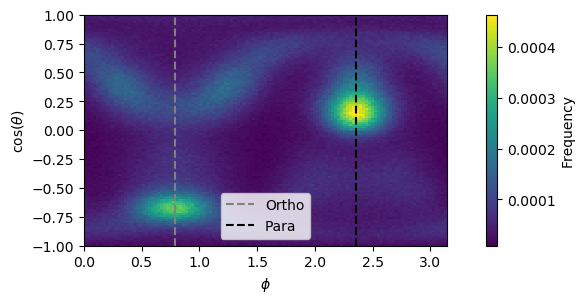

In [45]:

# Plot the histogram
plt.figure(figsize=(10, 3)) 
plt.imshow(combo_hist_OH_water["l_1"]/ norm_hist_OH_water["l_1"], interpolation='nearest', origin='lower',extent= ( 0 , np.pi,  -1,1  ) )
plt.colorbar(label='Frequency')
plt.xlabel(r'$\phi$')
plt.ylabel(r'cos($\theta$)')
plt.axvline(x=0.7854, color='grey', linestyle='--', label = 'Ortho')
plt.axvline(x=2.356, color='black', linestyle='--',  label = 'Para')
plt.legend()
#plt.title('2D Histogram')

# Show plot
plt.show()

In [22]:

#save histograms combo bins

folder_hist=path_of_runs+run_folder+"histogram_angular_combo/"
np.save(folder_hist+'theta_bins', ( theta_bins   ))
np.save(folder_hist+'phi_bins', ( phi_bins   ))

In [46]:

#save histograms combo



folder_hist=path_of_runs+run_folder+"histogram_angular_combo/"


make_folder(folder_hist)


hist_str='_hist_'
category=['dipole', 'OH_water', 'OH' ]
regions=['', '_oct', '_tet' ]
str_bins_centers='_bins_centers'

for cat in category:
    for reg in regions:
        print('combo'+hist_str+cat+reg+ "_" +surface_selection)
        #'combo'                                                                           #hist                         #normalization         
        np.save(folder_hist+'combo'+hist_str+cat+reg+ "_"+ surface_selection, ( eval('combo'+hist_str+cat+reg)   ,  eval("norm_hist_"+ cat +reg ) ))
np.save(folder_hist+'tot_time.txt', t)

combo_hist_dipole_u
combo_hist_dipole_oct_u
combo_hist_dipole_tet_u
combo_hist_OH_water_u
combo_hist_OH_water_oct_u
combo_hist_OH_water_tet_u
combo_hist_OH_u
combo_hist_OH_oct_u
combo_hist_OH_tet_u
